<a href="https://colab.research.google.com/github/su7ri/water-rainfall-river-overflow/blob/main/water_rainfall_river_overflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rainfall, River Flow and Storm Overflows in Devon & Cornwall
**Water-sector data analysis project · Soroush · October 2026**

*Open data: Environment Agency Hydrology API and South West Water 2025 Event Duration Monitoring (EDM) returns. Licence: Open Government Licence v3.*

---
## Summary

**Question.** How does rainfall drive river flow in the South West, and how closely do storm-overflow discharges follow rainfall?

**Data.** 7 rain gauges within 60 km of Exeter and 2 river-flow stations (River Exe at Thorverton, River Fal at Trenowth), daily, 2015–2025 (≈36,000 daily readings), plus 209,711 storm-overflow events across 1,179 South West Water sites in 2025.

**Key findings**
1. **Rain gauges agree with each other** (correlation 0.86–0.91 with the mean of the others), so a regional mean is a reasonable rainfall index.
2. **River Exe responds to rain within a day** (peak correlation at a 1-day lag, 0.54). **Antecedent wetness matters more than same-day rain:** the last 14 days of rainfall correlate 0.77 with log-flow, against 0.34 for the same day alone.
3. **A simple next-day flow model beats persistence** on 2023–24 test data: NSE 0.85 vs 0.78, RMSE 9.5 vs 11.5 m³/s. It still overshoots some flood peaks.
4. **Overflow activity follows rainfall.** In 2025, days with ≥10 mm of rain over the previous two days averaged ~1,580 overflow events per day, against ~250 on other days (Spearman 0.65 between daily events and 2-day rainfall).
5. **Rainfall alone does not explain everything.** December 2025 had about 72,000 events against about 39,000 in January with almost the same rainfall (206 vs 214 mm), and 2025 was not an unusually wet year (≈1,270 mm vs ≈1,530 mm in 2023).

6. **Low flow (water-resources angle).** Days with Exe flow below its long-run 10th percentile cluster in 2022 (133 days), 2018 (81) and 2025 (65), against 6–33 in the other years (SQL).
7. **Overflow impact is concentrated.** The worst 10% of sites account for about 47% of all discharge hours (SQL).

**Data-quality issues found and handled:** duplicate readings in one flow series, Suspect/Estimated/Unchecked readings (10.7% of the data), missing values, 356 overflow events longer than 7 days (likely monitor faults), and 2,207 events with no site name.

**Limitations.** Correlation is not causation; one catchment is modelled; the EDM data is unverified by the Environment Agency; event *counts* are not the same as discharge *volume or duration*.

---
**How to run:** Runtime ▸ Restart session and run all (about 3 minutes). Everything is downloaded from the public APIs; nothing is uploaded.

## 1. Setup

In [1]:
import io, time, pathlib
import requests                       # downloads from the APIs
import pandas as pd                   # tables
import numpy as np                    # numerics
import matplotlib.pyplot as plt       # charts
from sklearn.linear_model import Ridge   # simple forecasting model

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
BLUE, GREEN, ORANGE = "#2a6f97", "#1b4332", "#e76f51"

## 2. Configuration
Seven rain gauges around Exeter, two river-flow stations, and the study window (2015 to end of 2025, so the rainfall record covers the 2025 overflow data).

In [2]:
BASE  = "https://environment.data.gov.uk/hydrology"
START, END = "2015-01-01", "2026-01-01"          # END is exclusive
DATA  = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

RAIN = {   # station name: Environment Agency station GUID
    "Werrington_Park":   "68504bb6-817a-4ba1-b6b3-e59a08cac69f",
    "Hemyock":           "80786ae5-4dd1-4c30-8206-c7e62cf7ccb0",
    "Tiverton":          "303c52b4-4ead-4a5f-8c82-6b38027de4d8",
    "Ashcombe":          "4e00b4e3-af60-47cf-afe7-b36ac774ca82",
    "Bickington":        "31653dd5-c1ed-4091-a860-5e8d25936861",
    "Bellever_Dartmoor": "723a8fc4-908b-4430-91c7-9990be86540a_363307",
    "Roadford":          "c37097ef-dcae-43ef-b3e9-56584bf0b7eb",
}
FLOW = {
    "Exe_Thorverton": "3c4d4f78-2d0e-474a-b884-65a9daca18fb",
    "Fal_Trenowth":   "ddb6b643-06b0-4e48-b74c-f12f6f946968",
}
EDM_URL = ("https://environment.data.gov.uk/api/file/download?"
           "fileDataSetId=c95ecc47-fa70-4a24-b8cc-098232987526&"
           "fileName=South%20West%20Water%202025%20Detailed%20EDM%20Data.csv")

## 3. Data acquisition
Daily rainfall totals and daily mean flow come from the Hydrology API's *qualified* measures. The API allows one request at a time, so stations are downloaded sequentially with retries. Files already on disk are reused.

In [3]:
def get(url, params=None, tries=3):
    # Retry with back-off; raise if all attempts fail
    for i in range(tries):
        try:
            r = requests.get(url, params=params, timeout=180,
                             headers={"User-Agent": "portfolio-project/1.0"})
            if r.status_code == 200:
                return r
            print("  HTTP", r.status_code)
        except requests.RequestException as e:
            print("  error:", e)
        time.sleep(3 * (i + 1))
    raise RuntimeError("Download failed: " + url)

def download_series(name, measure_id, kind):
    path = DATA / f"{kind}_{name}.csv"
    if path.exists():
        return pd.read_csv(path)
    r = get(f"{BASE}/id/measures/{measure_id}/readings.csv",
            {"mineq-date": START, "max-date": END, "_limit": 100000})
    df = pd.read_csv(io.StringIO(r.text))
    df.insert(0, "series", name)
    df["kind"] = kind                    # rainfall_mm or flow_m3s
    df.to_csv(path, index=False)
    time.sleep(2)                        # one request at a time
    return df

frames = []
for name, guid in RAIN.items():
    print("rainfall:", name)
    frames.append(download_series(name, f"{guid}-rainfall-t-86400-mm-qualified", "rainfall_mm"))
for name, guid in FLOW.items():
    print("flow:", name)
    frames.append(download_series(name, f"{guid}-flow-m-86400-m3s-qualified", "flow_m3s"))
raw = pd.concat(frames, ignore_index=True)
print("raw readings:", len(raw))

rainfall: Werrington_Park
rainfall: Hemyock
rainfall: Tiverton
rainfall: Ashcombe
rainfall: Bickington
rainfall: Bellever_Dartmoor
rainfall: Roadford
flow: Exe_Thorverton
flow: Fal_Trenowth
raw readings: 36528


In [ ]:
# South West Water 2025 storm-overflow (EDM) returns: one row per discharge event
edm_path = DATA / "sww_edm_2025.csv"
FILE_API = "https://environment.data.gov.uk/api/file/download"
FILE_PARAMS = {"fileDataSetId": "c95ecc47-fa70-4a24-b8cc-098232987526",
               "fileName": "South West Water 2025 Detailed EDM Data.csv"}
BROWSER_UA = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                            "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"}

def try_download_edm():
    # The EA file service is sometimes flaky, so try several equivalent request styles.
    attempts = [
        ("encoded URL",        dict(url=EDM_URL)),
        ("params, plain UA",   dict(url=FILE_API, params=FILE_PARAMS)),
        ("params, browser UA", dict(url=FILE_API, params=FILE_PARAMS, headers=BROWSER_UA)),
        ("raw spaces URL",     dict(url=FILE_API + "?fileDataSetId=" + FILE_PARAMS["fileDataSetId"]
                                    + "&fileName=" + FILE_PARAMS["fileName"], headers=BROWSER_UA)),
    ]
    for label, kw in attempts:
        for wait in (0, 5):                       # one retry after a short pause
            time.sleep(wait)
            try:
                r = requests.get(timeout=300, **kw)
            except requests.RequestException as e:
                print(f"  {label}: error {e}"); continue
            if r.status_code == 200 and r.content[:9] == b"Unique ID":   # looks like the real CSV
                print(f"  downloaded with: {label} ({len(r.content)/1e6:.1f} MB)")
                return r.content
            print(f"  {label}: HTTP {r.status_code}")
    return None

if not edm_path.exists():
    content = try_download_edm()
    if content is None:
        # Fallback: download the file manually from the Defra Data Services Platform
        # (data.gov.uk dataset "Event Duration Monitoring - Storm Overflow - Start/Stop Detailed Data",
        # file "South West Water 2025 Detailed EDM Data.csv") and upload it here.
        print("Automatic download failed. Please upload the EDM CSV file now.")
        from google.colab import files
        up = files.upload()                                   # opens a file picker
        name, content = next(iter(up.items()))
        # Accept either the CSV itself or a .zip that contains it (e.g. sww_data.zip from the first run)
        if name.lower().endswith(".zip"):
            import zipfile
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                members = [m for m in z.namelist() if m.lower().endswith("sww_edm_2025.csv")]
                if not members:
                    raise FileNotFoundError("sww_edm_2025.csv was not found inside " + name)
                content = z.read(members[0])
        content = content.lstrip(bytes([0xEF, 0xBB, 0xBF]))      # drop a UTF-8 BOM if present
    if content[:9] != b"Unique ID":
        raise ValueError("This does not look like the EDM CSV (it should start with 'Unique ID'). "
                         "Upload sww_edm_2025.csv or the zip that contains it.")
    edm_path.write_bytes(content)
edm = pd.read_csv(edm_path)
print(edm.shape)
# Sanity check: the full South West Water 2025 file has about 209,700 rows and 1,179 sites.
# A much smaller file means a partial or different file was used, and the numbers in the Summary will not match.
if len(edm) < 150_000:
    print("WARNING: only", len(edm), "rows. Expected about 209,711. Check you uploaded the full EDM file (about 15 MB).")
edm.head()

## 4. Data quality assessment
The Environment Agency labels every reading: *Good, Estimated, Suspect, Unchecked, Missing*. Before analysing anything I measure how much of the record is not fully trusted, per station.

In [5]:
qa = (raw.assign(missing_value=raw.value.isna())
         .groupby("series").agg(rows=("value", "size"), missing_values=("missing_value", "sum")))
qa = qa.join(pd.crosstab(raw.series, raw.quality))
qa["pct_not_good"] = ((qa.rows - qa.get("Good", 0)) / qa.rows * 100).round(1)
qa

,rows,missing_values,Estimated,Good,Missing,Suspect,Unchecked,pct_not_good
series,,,,,,,,
Ashcombe,4018,0,0,3379,0,0,639,15.9
Bellever_Dartmoor,4018,6,0,3438,6,263,311,14.4
Bickington,4018,7,0,3909,7,102,0,2.7
Exe_Thorverton,4018,0,549,3469,0,0,0,13.7
Fal_Trenowth,4384,0,73,4265,0,3,43,2.7
Hemyock,4018,0,0,3096,0,817,105,22.9
Roadford,4018,12,0,3836,12,32,138,4.5
Tiverton,4018,5,0,3898,5,114,1,3.0
Werrington_Park,4018,0,0,3289,0,529,200,18.1


**Finding.** `Fal_Trenowth` has 4,019 rows against 3,653 for the others. Duplicates by date explain the difference:

In [6]:
dups = raw.groupby("series").date.apply(lambda s: s.duplicated().sum())
print("duplicate dates per station:"); print(dups[dups > 0])
print("\nreading times in Fal_Trenowth:")
print(raw[raw.series == "Fal_Trenowth"].dateTime.str[11:].value_counts())

duplicate dates per station:
series
Fal_Trenowth    366
Name: date, dtype: int64

reading times in Fal_Trenowth:
dateTime
09:00:00    4018
00:00:00     366
Name: count, dtype: int64


For one year the Fal series carries two readings per day (00:00 and 09:00). All other stations use the 09:00 daily reading, so I keep **09:00 only** to keep the series consistent. This decision is documented in the cleaning step.

## 5. Cleaning

In [7]:
clean = raw.copy()
clean = clean[clean.dateTime.str[11:] == "09:00:00"]          # 1) one reading per day (09:00 hydrological day)
clean["date"] = pd.to_datetime(clean.date)                     # 2) proper date type
clean.loc[clean.quality == "Missing", "value"] = np.nan        # 3) Missing -> NaN, never zero
clean["flag_suspect"] = clean.quality.isin(["Suspect", "Estimated", "Unchecked"])   # 4) keep, but flag
assert clean.duplicated(["series", "date"]).sum() == 0         # check: one row per station per day
print(f"rows: {len(raw):,} -> {len(clean):,}")
print(f"not fully trusted: {clean.flag_suspect.mean():.1%} of readings")

rows: 36,528 -> 36,162
not fully trusted: 10.7% of readings


In [8]:
# Wide table: one column per station, one row per day
wide = clean.pivot(index="date", columns="series", values="value")
rain_cols = list(RAIN)

# Regional rainfall index: mean of gauges, excluding Suspect readings (conservative choice)
rain_ok = (clean[clean.kind == "rainfall_mm"]
           .assign(v=lambda x: x.value.where(x.quality != "Suspect"))
           .pivot(index="date", columns="series", values="v"))
wide["rain_mean_good"] = rain_ok.mean(axis=1)
wide[["rain_mean_good", "Exe_Thorverton", "Fal_Trenowth"]].describe().round(2)

series,rain_mean_good,Exe_Thorverton,Fal_Trenowth
count,4018.00,4018.00,4018.00
mean,3.45,16.76,1.71
std,5.98,19.81,1.37
min,0.00,1.23,0.04
25%,0.04,3.87,0.70
50%,0.66,8.17,1.33
75%,4.47,22.60,2.37
max,50.76,193.56,10.18


## 6. Do the rain gauges agree?
If each gauge correlates strongly with the others, their mean is a fair index of regional rainfall.

In [9]:
agree = pd.Series({c: wide[c].corr(wide[[x for x in rain_cols if x != c]].mean(axis=1)) for c in rain_cols})
agree.round(2).rename("correlation with mean of other gauges").to_frame()

,correlation with mean of other gauges
Werrington_Park,0.86
Hemyock,0.87
Tiverton,0.86
Ashcombe,0.86
Bickington,0.91
Bellever_Dartmoor,0.88
Roadford,0.88


## 7. Rainfall and river flow
The River Exe (catchment ≈ 601 km²) responds quickly to rain and recedes slowly. Winter 2023–24 shows the pattern.

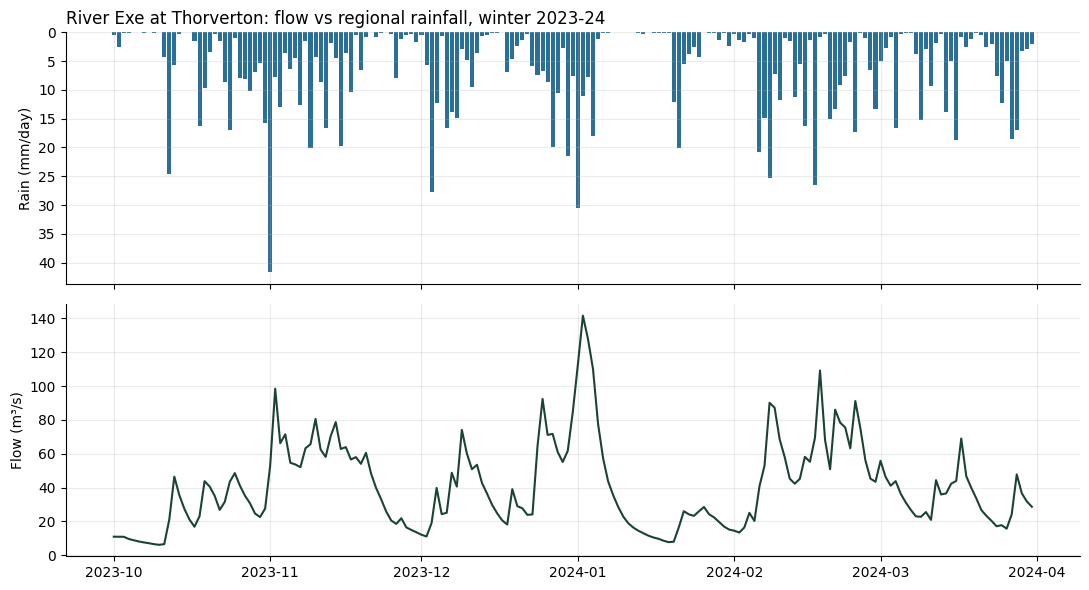

In [10]:
s = slice("2023-10-01", "2024-03-31")
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].bar(wide.loc[s].index, wide.loc[s, "rain_mean_good"], color=BLUE)
ax[0].invert_yaxis(); ax[0].set_ylabel("Rain (mm/day)")
ax[0].set_title("River Exe at Thorverton: flow vs regional rainfall, winter 2023-24", loc="left")
ax[1].plot(wide.loc[s].index, wide.loc[s, "Exe_Thorverton"], color=GREEN); ax[1].set_ylabel("Flow (m³/s)")
plt.tight_layout(); plt.show()

**How quickly does the river respond?** Correlation between flow today and rainfall *n* days earlier:

In [11]:
exe = wide.Exe_Thorverton
lag = pd.Series({n: exe.corr(wide.rain_mean_good.shift(n)) for n in range(6)}, name="correlation")
lag.index.name = "lag (days)"; lag.round(2).to_frame()

,correlation
lag (days),
0,0.37
1,0.54
2,0.45
3,0.42
4,0.39
5,0.35


**How long is the river's memory?** Correlation between log-flow and rainfall accumulated over the previous *w* days:

In [12]:
mem = pd.Series({w: np.log1p(exe).corr(wide.rain_mean_good.rolling(w).sum()) for w in (1, 3, 7, 14, 30)}, name="correlation")
mem.index.name = "window (days)"; mem.round(2).to_frame()

,correlation
window (days),
1,0.34
3,0.57
7,0.71
14,0.77
30,0.77


**Takeaway.** The river reacts within a day, but accumulated rainfall over about two weeks explains flow far better than same-day rain: soil and groundwater storage matter. This is why the forecasting model below uses rolling rainfall totals.

## 8. Forecasting next-day flow
Two models are compared on held-out data (train 2015–2022, test 2023–2024; the test period is never used in training):
- **Persistence baseline:** tomorrow equals today. Any useful model must beat this.
- **Ridge regression:** previous flows, rainfall (today, yesterday, 3/7/30-day totals) and seasonality, fitted on log-flow.

Metric: Nash–Sutcliffe Efficiency (NSE), standard in hydrology (1 = perfect, 0 = no better than the mean), plus RMSE in m³/s.

In [13]:
r = wide.rain_mean_good.fillna(0)
logq = np.log1p(exe)
doy = wide.index.dayofyear
X = pd.DataFrame({
    "q_yesterday": logq.shift(1), "q_2days": logq.shift(2),
    "rain_today": r, "rain_yest": r.shift(1),
    "rain_3d": r.rolling(3).sum().shift(1), "rain_7d": r.rolling(7).sum().shift(1),
    "rain_30d": r.rolling(30).sum().shift(1),
    "season_sin": np.sin(2*np.pi*doy/365.25), "season_cos": np.cos(2*np.pi*doy/365.25),
})
ok    = X.notna().all(axis=1) & logq.notna()
train = ok & (X.index < "2023-01-01")
test  = ok & (X.index >= "2023-01-01") & (X.index < "2025-01-01")

model = Ridge(alpha=1.0).fit(X[train], logq[train])
pred  = pd.Series(np.expm1(model.predict(X[test])), index=X[test].index)   # back to m3/s
obs, base = exe[test], exe.shift(1)[test]

nse  = lambda o, s: 1 - ((o - s)**2).sum() / ((o - o.mean())**2).sum()
rmse = lambda o, s: float(np.sqrt(((o - s)**2).mean()))
pd.DataFrame({"NSE": [nse(obs, base), nse(obs, pred)], "RMSE (m3/s)": [rmse(obs, base), rmse(obs, pred)]},
             index=["Persistence", "Ridge"]).round(3)

,NSE,RMSE (m3/s)
Persistence,0.782,11.493
Ridge,0.853,9.452


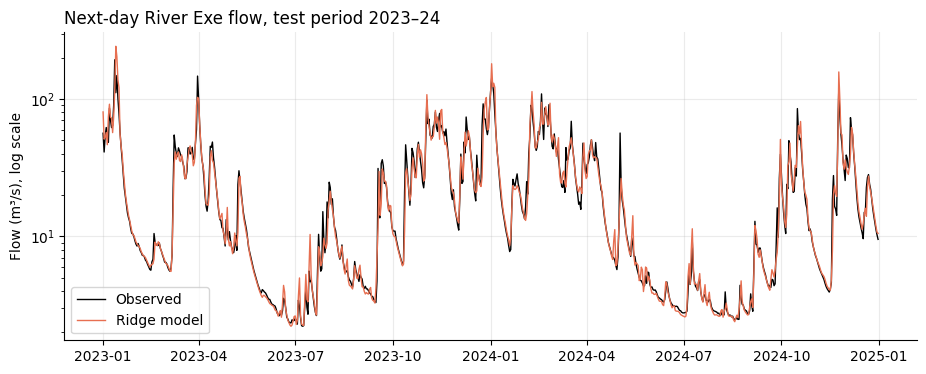

In [14]:
fig, ax = plt.subplots()
ax.plot(obs.index, obs, color="k", lw=1, label="Observed")
ax.plot(pred.index, pred, color=ORANGE, lw=1, label="Ridge model")
ax.set_yscale("log"); ax.set_ylabel("Flow (m³/s), log scale")
ax.set_title("Next-day River Exe flow, test period 2023–24", loc="left"); ax.legend()
plt.show()

In [15]:
# Where does the model struggle? Compare error on the highest-flow days
hi = obs >= obs.quantile(.95)
print(f"Top-5% flow days: Ridge RMSE {rmse(obs[hi], pred[hi]):.1f} vs persistence {rmse(obs[hi], base[hi]):.1f} m3/s")
print(f"Mean signed error on those days: {(pred[hi] - obs[hi]).mean():+.1f} m3/s (positive = over-prediction)")

Top-5% flow days: Ridge RMSE 35.6 vs persistence 40.1 m3/s
Mean signed error on those days: +4.5 m3/s (positive = over-prediction)


**Takeaway.** A transparent model with rainfall memory beats persistence (NSE 0.85 vs 0.78), but it is weakest at flood peaks, which matter most operationally. Next steps would be gradient boosting, more catchments and rainfall-forecast inputs.

## 9. Storm overflows (EDM), South West Water 2025
Each row is one discharge event. Cleaning rules:
- duration = stop − start;
- events longer than 7 days are flagged **and excluded** from counts (likely monitor faults or unclosed events);
- events without a site name are kept but reported.

In [16]:
edm.columns = ["site_id", "site_name", "start", "stop"]
edm["start"], edm["stop"] = pd.to_datetime(edm.start), pd.to_datetime(edm.stop)
edm["hours"] = (edm.stop - edm.start).dt.total_seconds() / 3600
edm["too_long"] = edm.hours > 24 * 7
pd.Series({
    "events": len(edm), "sites": edm.site_id.nunique(),
    "events without site name": int(edm.site_name.isna().sum()),
    "events longer than 7 days (excluded)": int(edm.too_long.sum()),
    "longest event (hours)": round(edm.hours.max()),
    "median event (minutes)": round(edm.hours.median() * 60, 1),
}, name="value").to_frame()

,value
events,209711.0
sites,1179.0
events without site name,2207.0
events longer than 7 days (excluded),356.0
longest event (hours),2329.0
median event (minutes),4.9


In [17]:
# Sites with the most discharge hours (excluding the >7-day events)
(edm[~edm.too_long].groupby(["site_id", "site_name"], dropna=False).hours.sum()
    .sort_values(ascending=False).head(10).round(0).to_frame("discharge hours, 2025"))

,,"discharge hours, 2025"
site_id,site_name,
SBB00357,DELABOLE WASTEWATER TREATMENT WORKS,2903.0
SBB01024,REWE WASTEWATER TREATMENT WORKS,2568.0
SBB01407,NaN,2187.0
SBB01396,PAYHEMBURY STW,2058.0
SBB01101,SOUTH MOLTON WWTW,2014.0
SBB01209,TATWORTH WWTW,1978.0
SBB00568,HIGH BICKINGTON STW,1912.0
SBB00464,FOLLY GATE WWTW SSO,1813.0
SBB00155,BRIDGE PS / CSO / EO,1749.0


### Do overflows follow rainfall?
For each day of 2025: number of events that started, against the regional rainfall of that day and the previous two days. Spearman correlation is used because the distributions are skewed.

In [18]:
edm["date"] = edm.start.dt.tz_localize(None).dt.normalize()
events_daily = (edm[~edm.too_long].groupby("date").size()
                  .reindex(pd.date_range("2025-01-01", "2025-12-31"), fill_value=0))
rain25 = wide.loc["2025-01-01":"2025-12-31", "rain_mean_good"]
assert rain25.notna().all(), "2025 rainfall missing: delete the data folder and re-run the download"

comp = pd.DataFrame({"events": events_daily, "rain": rain25,
                     "rain_prev": rain25.shift(1), "rain_2d": rain25.rolling(2).sum()})
print(comp.corr(method="spearman").round(2)["events"].drop("events").rename("Spearman with daily events"))

rain         0.53
rain_prev    0.57
rain_2d      0.65
Name: Spearman with daily events, dtype: float64


In [19]:
comp["wet"] = comp.rain_2d >= 10
summary = comp.groupby("wet").events.agg(days="count", mean="mean", median="median").round(0)
summary.index = ["Other days (<10 mm in 2 days)", "Wet days (>=10 mm in 2 days)"]
summary

,days,mean,median
Other days (<10 mm in 2 days),276,248.0,54.0
Wet days (>=10 mm in 2 days),89,1584.0,1182.0


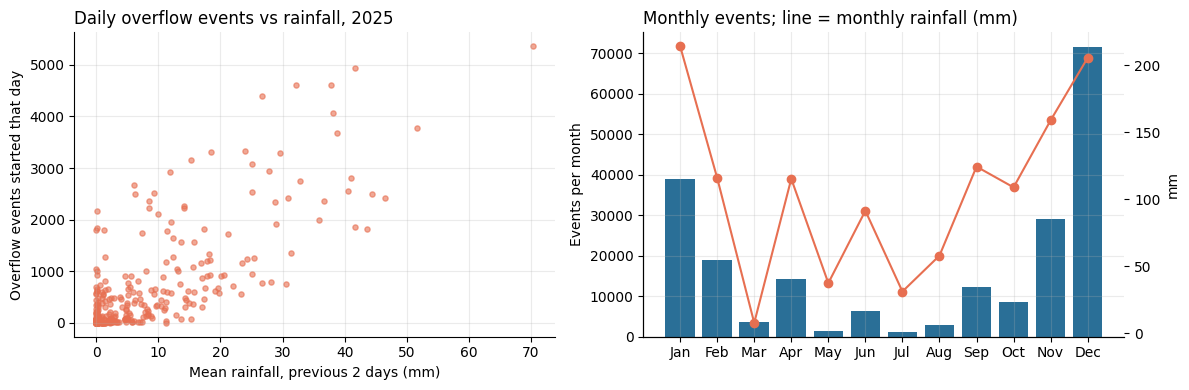

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(comp.rain_2d, comp.events, s=14, alpha=.6, color=ORANGE)
ax[0].set_xlabel("Mean rainfall, previous 2 days (mm)"); ax[0].set_ylabel("Overflow events started that day")
ax[0].set_title("Daily overflow events vs rainfall, 2025", loc="left")
monthly = comp.resample("ME").agg({"events": "sum", "rain": "sum"})
ax[1].bar(monthly.index.strftime("%b"), monthly.events, color=BLUE); ax[1].set_ylabel("Events per month")
ax[1].set_title("Monthly events; line = monthly rainfall (mm)", loc="left")
b = ax[1].twinx(); b.plot(monthly.index.strftime("%b"), monthly.rain, color=ORANGE, marker="o"); b.set_ylabel("mm"); b.grid(False)
plt.tight_layout(); plt.show()

**Takeaway.** Overflow activity rises sharply with rainfall (about 6× more events on wet days). But rainfall is not the whole story: December had far more events than January for the same rainfall. Possible explanations include saturated ground after a wet autumn, system capacity or operational changes, and monitoring differences. The data here cannot separate them, so I report the pattern without claiming a cause.

Note that these are **event counts**: one storm can trigger the same site repeatedly, and the median event lasts only about 5 minutes. Total discharge **duration** is a better measure of impact, and discharge **volume** would be better still (not available in this dataset).

## 10. SQL analysis
The cleaned tables are loaded into an in-notebook **SQLite** database (no server needed) with a small star schema: `dim_date`, `dim_station`, `fact_daily_readings`, `fact_edm_events` and `fact_edm_daily`. The queries are standard SQL and port to PostgreSQL or SQL Server with minor syntax changes. SQL is used here for what it does best: aggregation, window functions, percentiles and concentration analysis.

In [21]:
import sqlite3
con = sqlite3.connect(DATA / "water.sqlite")      # a real database file, also openable in DB Browser for SQLite
dates = pd.date_range("2015-01-01", "2025-12-31")
pd.DataFrame({"date": dates.strftime("%Y-%m-%d"), "year": dates.year, "month_num": dates.month,
              "month": dates.strftime("%b")}).to_sql("dim_date", con, index=False, if_exists="replace")
pd.DataFrame({"station": list(RAIN) + list(FLOW),
              "measure": ["Rainfall"]*len(RAIN) + ["River flow"]*len(FLOW)}).to_sql("dim_station", con, index=False, if_exists="replace")
fdr = clean[["date", "series", "value", "quality"]].rename(columns={"series": "station"}).copy()
fdr["date"] = fdr.date.dt.strftime("%Y-%m-%d")
fdr.to_sql("fact_daily_readings", con, index=False, if_exists="replace")
ev = edm[["site_id", "site_name", "hours", "too_long", "date"]].copy()
ev["site_name"] = ev.site_name.fillna("Unknown"); ev["too_long"] = ev.too_long.astype(int)
ev["date"] = ev.date.dt.strftime("%Y-%m-%d")
ev.to_sql("fact_edm_events", con, index=False, if_exists="replace")
ed = (ev[ev.too_long == 0].groupby("date")
        .agg(events=("hours", "size"), discharge_hours=("hours", "sum"), sites_active=("site_id", "nunique"))
        .reindex(pd.date_range("2025-01-01", "2025-12-31").strftime("%Y-%m-%d"), fill_value=0)
        .rename_axis("date").reset_index())
ed.to_sql("fact_edm_daily", con, index=False, if_exists="replace")

def q(sql):
    # helper: run a SQL query and return a DataFrame
    return pd.read_sql(sql, con)
print(q("SELECT name FROM sqlite_master WHERE type='table'").name.tolist())

['dim_date', 'dim_station', 'fact_daily_readings', 'fact_edm_events', 'fact_edm_daily']


### Q1 · Data quality: share of readings that are not "Good", per station
Hemyock and Werrington Park have the highest share of non-Good readings, so results that rely on them deserve more caution.

In [22]:
q("""
SELECT station,
       COUNT(*)                                        AS readings,
       SUM(value IS NULL)                              AS missing,
       ROUND(100.0 * SUM(quality <> 'Good') / COUNT(*), 1) AS pct_not_good
FROM fact_daily_readings
GROUP BY station
ORDER BY pct_not_good DESC
""")

,station,readings,missing,pct_not_good
0,Hemyock,4018,0,22.9
1,Werrington_Park,4018,0,18.1
2,Ashcombe,4018,0,15.9
3,Bellever_Dartmoor,4018,6,14.4
4,Exe_Thorverton,4018,0,13.7
5,Roadford,4018,12,4.5
6,Tiverton,4018,5,3.0
7,Bickington,4018,7,2.7
8,Fal_Trenowth,4018,0,1.5


### Q2 · Regional daily rainfall index (mean of gauges, Suspect excluded)
Mean of the seven gauges per day, excluding Suspect readings, saved as a view so later queries stay short.

In [23]:
con.executescript("""
CREATE VIEW IF NOT EXISTS v_rain_daily AS
SELECT r.date, AVG(r.value) AS rain_mm
FROM fact_daily_readings r
JOIN dim_station s ON s.station = r.station
WHERE s.measure = 'Rainfall' AND r.quality <> 'Suspect'
GROUP BY r.date;
""")
q("SELECT * FROM v_rain_daily LIMIT 5")

,date,rain_mm
0,2015-01-01,7.04
1,2015-01-02,15.82
2,2015-01-03,1.38
3,2015-01-04,0.04
4,2015-01-05,2.10


### Q3 · Annual rainfall and wettest month per year
Annual totals and the wettest month, as a sanity check against the Python results.

In [24]:
q("""
WITH monthly AS (
  SELECT d.year, d.month, d.month_num, SUM(v.rain_mm) AS rain_mm
  FROM v_rain_daily v JOIN dim_date d ON d.date = v.date
  GROUP BY d.year, d.month_num
)
SELECT year,
       ROUND(SUM(rain_mm)) AS annual_mm,
       (SELECT m2.month FROM monthly m2 WHERE m2.year = m.year
        ORDER BY m2.rain_mm DESC LIMIT 1) AS wettest_month
FROM monthly m GROUP BY year ORDER BY year
""")

,year,annual_mm,wettest_month
0,2015,1142.0,Dec
1,2016,992.0,Jan
2,2017,1074.0,Dec
3,2018,1248.0,Nov
4,2019,1337.0,Oct
5,2020,1393.0,Feb
6,2021,1279.0,Oct
7,2022,1118.0,Nov
8,2023,1533.0,Mar
9,2024,1478.0,Feb


### Q4 · Rolling 14-day rainfall and Exe flow (window function)
Window functions give rolling 2- and 14-day rainfall next to Exe flow. The view is reused by later queries.

In [25]:
con.executescript("""
CREATE VIEW IF NOT EXISTS v_rain_flow AS
SELECT v.date,
       v.rain_mm,
       SUM(v.rain_mm) OVER (ORDER BY v.date ROWS BETWEEN 13 PRECEDING AND CURRENT ROW) AS rain_14d,
       SUM(v.rain_mm) OVER (ORDER BY v.date ROWS BETWEEN 1 PRECEDING AND CURRENT ROW)  AS rain_2d,
       f.value AS exe_flow
FROM v_rain_daily v
LEFT JOIN fact_daily_readings f ON f.date = v.date AND f.station = 'Exe_Thorverton';
""")
q("SELECT * FROM v_rain_flow WHERE exe_flow IS NOT NULL LIMIT 5")

,date,rain_mm,rain_14d,rain_2d,exe_flow
0,2015-01-01,7.04,7.04,7.04,22.952
1,2015-01-02,15.82,22.86,22.86,27.918
2,2015-01-03,1.38,24.24,17.20,67.186
3,2015-01-04,0.04,24.28,1.42,44.268
4,2015-01-05,2.10,26.38,2.14,34.611


### Q5 · Flow response: average Exe flow by 14-day rainfall band
Mean flow rises steeply with 14-day rainfall (about 5 m³/s under 20 mm against about 50 m³/s for 100 mm or more), confirming the river has a long memory.

In [26]:
q("""
SELECT CASE WHEN rain_14d < 20  THEN '1: <20 mm'
            WHEN rain_14d < 50  THEN '2: 20-50 mm'
            WHEN rain_14d < 100 THEN '3: 50-100 mm'
            ELSE '4: >=100 mm' END AS rain_14d_band,
       COUNT(*) AS days,
       ROUND(AVG(exe_flow), 1) AS avg_flow_m3s
FROM v_rain_flow
WHERE rain_14d IS NOT NULL AND exe_flow IS NOT NULL
GROUP BY 1 ORDER BY 1
""")

,rain_14d_band,days,avg_flow_m3s
0,1: <20 mm,1092,4.6
1,2: 20-50 mm,1302,9.6
2,3: 50-100 mm,1194,23.8
3,4: >=100 mm,430,49.7


### Q6 · Low-flow days per year (Exe below its own 10th percentile) - water resources angle
**Water-resources angle.** Low-flow days cluster in a few years: 2022 (133 days), 2018 (81) and 2025 (65), against 6–33 in the other years. This matches the dry summers of 2018 and 2022 and shows 2025 was also a low-flow year despite near-average rainfall. Low-flow frequency matters for abstraction and supply planning.

In [27]:
q("""
WITH ranked AS (
  SELECT date, value,
         PERCENT_RANK() OVER (ORDER BY value) AS pr
  FROM fact_daily_readings WHERE station = 'Exe_Thorverton' AND value IS NOT NULL
)
SELECT substr(date, 1, 4) AS year,
       SUM(pr <= 0.10) AS low_flow_days,
       ROUND(MIN(value), 2) AS min_flow_m3s
FROM ranked GROUP BY 1 ORDER BY 1
""")

,year,low_flow_days,min_flow_m3s
0,2015,6,2.35
1,2016,12,2.45
2,2017,7,2.34
3,2018,81,1.40
4,2019,19,2.11
5,2020,33,1.83
6,2021,12,2.22
7,2022,133,1.23
8,2023,19,2.22
9,2024,15,2.48


### Q7 · Overflows: wet days vs other days (2025)
Same wet/dry comparison as in Python; discharge hours show an even bigger difference than event counts.

In [28]:
q("""
SELECT CASE WHEN rf.rain_2d >= 10 THEN 'Wet (>=10 mm in 2 days)' ELSE 'Other' END AS day_type,
       COUNT(*) AS days,
       ROUND(AVG(e.events)) AS avg_events,
       ROUND(AVG(e.discharge_hours)) AS avg_discharge_hours
FROM fact_edm_daily e JOIN v_rain_flow rf ON rf.date = e.date
GROUP BY 1
""")

,day_type,days,avg_events,avg_discharge_hours
0,Other,275,246.0,201.0
1,Wet (>=10 mm in 2 days),90,1575.0,2568.0


### Q8 · Top 10 sites by total discharge hours (events > 7 days excluded)
The sites with the longest total discharge time. One top site has no name in the returns.

In [29]:
q("""
SELECT site_id,
       COALESCE(NULLIF(site_name, 'Unknown'), '(no name)') AS site_name,
       COUNT(*) AS events,
       ROUND(SUM(hours)) AS discharge_hours,
       ROUND(100.0 * SUM(hours) / (SELECT SUM(hours) FROM fact_edm_events WHERE too_long = 0), 2) AS pct_of_total
FROM fact_edm_events
WHERE too_long = 0
GROUP BY site_id, site_name
ORDER BY discharge_hours DESC
LIMIT 10
""")

,site_id,site_name,events,discharge_hours,pct_of_total
0,SBB00357,DELABOLE WASTEWATER TREATMENT WORKS,1564,2903.0,1.01
1,SBB01024,REWE WASTEWATER TREATMENT WORKS,2762,2568.0,0.90
2,SBB01407,(no name),145,2187.0,0.76
3,SBB01396,PAYHEMBURY STW,266,2058.0,0.72
4,SBB01101,SOUTH MOLTON WWTW,733,2014.0,0.70
5,SBB01209,TATWORTH WWTW,133,1978.0,0.69
6,SBB00568,HIGH BICKINGTON STW,1110,1912.0,0.67
7,SBB00464,FOLLY GATE WWTW SSO,75,1813.0,0.63
8,SBB00155,BRIDGE PS / CSO / EO,541,1749.0,0.61
9,SBB00435,EXTON SOUTH PUMPING STATION,344,1741.0,0.61


### Q9 · Share of all discharge hours caused by the worst 10% of sites (concentration)
Impact is concentrated: the worst 10% of sites account for nearly half of all discharge hours, which suggests where investigation would pay off most.

In [30]:
q("""
WITH site AS (
  SELECT site_id, SUM(hours) AS h FROM fact_edm_events WHERE too_long = 0 GROUP BY site_id
), ranked AS (
  SELECT h, NTILE(10) OVER (ORDER BY h DESC) AS decile FROM site
)
SELECT decile, COUNT(*) AS sites, ROUND(100.0 * SUM(h) / (SELECT SUM(h) FROM site), 1) AS pct_of_hours
FROM ranked GROUP BY decile ORDER BY decile
""")

,decile,sites,pct_of_hours
0,1,118,46.6
1,2,118,24.3
2,3,118,13.7
3,4,118,7.9
4,5,118,4.0
5,6,118,2.0
6,7,118,1.0
7,8,118,0.3
8,9,118,0.1
9,10,117,0.0


### Q10 · Anomaly check: monitors with suspiciously long events (>7 days)
Monitors reporting events of more than 7 days (up to about 97 days). Likely faults or unclosed events, to be validated with the operator.

In [31]:
q("""
SELECT site_id, COALESCE(NULLIF(site_name,'Unknown'),'(no name)') AS site_name,
       COUNT(*) AS long_events, ROUND(MAX(hours)) AS longest_hours
FROM fact_edm_events WHERE too_long = 1
GROUP BY site_id ORDER BY longest_hours DESC LIMIT 10
""")

,site_id,site_name,long_events,longest_hours
0,SBB01043,SALCOMBE REGIS WWTW CSO,6,2329.0
1,SBB00148,BRAYFORD STW,3,1690.0
2,SBB01407,(no name),6,1649.0
3,SBB00980,PRAZE AN BEEBLE STW,4,1379.0
4,SBB00224,CHACEWATER STW,5,1340.0
5,SBB00957,PONSANOOTH STW SSO,3,1198.0
6,SBB00388,DUNSFORD WWTW,5,1183.0
7,SBB00526,GWENNAP WASTEWATER TREATMENT WORKS,3,1180.0
8,SBB00658,LAMERTON STW,3,1149.0
9,SBB00242,CHERITON FITZPAINE WWTW,5,997.0


### Q11 · Anomaly: days whose event count is >2 SD above that month's average (spikes to investigate)
Days where event counts spike well above that month's norm. Candidates for review (storm cells, monitor behaviour or reporting artefacts).

In [32]:
q("""
WITH m AS (
  SELECT e.date, e.events, rf.rain_2d, substr(e.date,1,7) AS ym FROM fact_edm_daily e
  JOIN v_rain_flow rf ON rf.date = e.date
), stats AS (
  SELECT ym, AVG(events) AS mu, AVG(events*events) - AVG(events)*AVG(events) AS var FROM m GROUP BY ym
)
SELECT m.date, m.events, ROUND(m.rain_2d,1) AS rain_2d_mm,
       ROUND((m.events - s.mu) / NULLIF(SQRT(s.var),0), 2) AS z_in_month
FROM m JOIN stats s USING (ym)
WHERE (m.events - s.mu) / NULLIF(SQRT(s.var),0) > 2
ORDER BY z_in_month DESC LIMIT 10
""")

,date,events,rain_2d_mm,z_in_month
0,2025-05-27,372,15.6,4.63
1,2025-07-20,310,14.2,4.43
2,2025-06-12,2349,28.8,4.33
3,2025-08-28,907,20.1,3.73
4,2025-03-02,665,0.0,3.44
5,2025-03-01,625,0.1,3.19
6,2025-11-12,2933,27.8,3.14
7,2025-01-05,5360,70.4,2.95
8,2025-10-20,1241,24.3,2.95
9,2025-02-24,2811,41.1,2.81


**Takeaways from SQL.** (1) Flow is strongly conditioned on 14-day rainfall. (2) Low-flow days cluster in 2022, 2018 and 2025. (3) Discharge impact is concentrated in a minority of sites. (4) Long-duration events and day-level spikes sit in specific sites and dates that merit validation.

## 11. Export for Power BI / reporting

In [33]:
clean.to_csv(DATA / "readings_clean_long.csv", index=False)
wide.to_csv(DATA / "daily_wide.csv")
comp.to_csv(DATA / "edm_vs_rain_daily_2025.csv")
import shutil
shutil.make_archive("sww_outputs", "zip", DATA)
try:
    from google.colab import files
    files.download("sww_outputs.zip")
except ImportError:
    print("sww_outputs.zip created next to the notebook.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Method, assumptions and limitations
| Topic | Decision / caveat |
|---|---|
| Rainfall index | Mean of 7 gauges, Suspect readings excluded; gauges correlate 0.86–0.91 |
| Flow data | Daily mean flow; Estimated readings kept but flagged (≈14% of Exe) |
| Fal duplicates | Two daily readings for one year; kept the 09:00 reading for consistency |
| Missing values | Set to NaN, never zero; rainfall gaps treated as 0 only in model features |
| EDM data | Self-reported by water companies, not verified by the Environment Agency; events >7 days excluded |
| Scope | One flow catchment modelled; 7 gauges; one year of overflow data |
| Inference | Correlation, not causation; counts are not volumes |

**Possible extensions:** more catchments and years of EDM data; discharge duration per site as the impact measure; gradient-boosted models and probabilistic forecasts; linking sites to receiving waters and bathing-water quality; a Power BI report on the exported tables.

*Sources: Environment Agency Hydrology API (environment.data.gov.uk/hydrology); Environment Agency / South West Water 2025 Detailed EDM Data. Contains public sector information licensed under the Open Government Licence v3.0.*